# Predicción de duración de taxis NYC: Fourier y Wavelets Haar
### Experimento reproducible para reducir RMSLE sin fuga de información

**Curso:** Sistemas Inteligentes — FES Acatlán, UNAM  
**Objetivo:** evaluar si el análisis espectral y las wavelets mejoran el modelo de regresión LightGBM existente.  
**Variable objetivo:** `trip_duration` (segundos); **métrica:** RMSLE, menor es mejor.

> Este notebook presenta las etapas, código y resultados **medidos**, incluidos experimentos descartados. **No se considera que 0.20 sea un resultado alcanzado** mientras no se haya validado. Se usan los módulos `features_taxi.py` y `wavelet_fft_taxi.py` incluidos en el ZIP.


## 1. Comprender la métrica

\[
\mathrm{RMSLE}=\sqrt{\frac{1}{n}\sum_{i=1}^n \left[\ln(1+\max(0,\hat y_i))-\ln(1+y_i)\right]^2}.
\]

`trip_duration` es continua: **regresión**, por eso no corresponde usar F1, accuracy, recall o precision. Se entrena con `z=log1p(trip_duration)` para que el RMSE del objetivo transformado se aproxime directamente al RMSLE.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from features_taxi import create_features
from wavelet_fft_taxi import deterministic_features, FourierHaarEncoder, haar_scales, rmsle
R = Path.cwd()
print('Proyecto:', R)


Proyecto: /mnt/data


## 2. Auditoría inicial (antes de tocar los datos)

Se comprueban columnas, faltantes, duración extrema, duplicidad de IDs y período de cobertura. Los viajes extremos se mantienen en validación y en holdout: eliminarlos de la evaluación artificialmente mejoraría la métrica.


In [2]:
train = pd.read_csv(R/'train.csv',parse_dates=['pickup_datetime'])
test = pd.read_csv(R/'test.csv',parse_dates=['pickup_datetime'])
print('Entrenamiento:',train.shape,' | Prueba ciega:',test.shape)
print('Faltantes train:\n',train.isna().sum().to_string())
print('IDs duplicados train/test:',train.id.duplicated().sum(),test.id.duplicated().sum())
print('Duraciones > 12 h:',int((train.trip_duration>43200).sum()))
print('Percentiles de la duración (s):\n',train.trip_duration.quantile([0,.25,.50,.75,.95,.99,.999,1]).round(1))
print('Fechas:',train.pickup_datetime.min(),train.pickup_datetime.max())
assert 'trip_duration' not in test.columns


Entrenamiento: (700000, 10)  | Prueba ciega: (100000, 9)
Faltantes train:
 id                    0
vendor_id             0
pickup_datetime       0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
IDs duplicados train/test: 0 0
Duraciones > 12 h: 984
Percentiles de la duración (s):
 0.000          1.0
0.250        397.0
0.500        662.0
0.750       1076.0
0.950       2106.0
0.990       3441.0
0.999      85220.0
1.000    3526282.0
Name: trip_duration, dtype: float64
Fechas: 2016-01-01 00:00:17 2016-06-30 23:59:39


## 3. Descubrir ciclos con la transformada rápida de Fourier (FFT)

Se agrupan los **pickups del entrenamiento** en intervalos de 30 minutos. Este cálculo no usa `trip_duration`. La FFT permite detectar periodicidades, especialmente los ciclos de **12 h, 24 h y 168 h** observados en los datos de esta práctica. El espectro por sí solo no demuestra que mejoren las predicciones.

\[
X_k=\sum_{t=0}^{N-1}x_t\,e^{-2\pi i kt/N},\qquad P_k=|X_k|^2.
\]


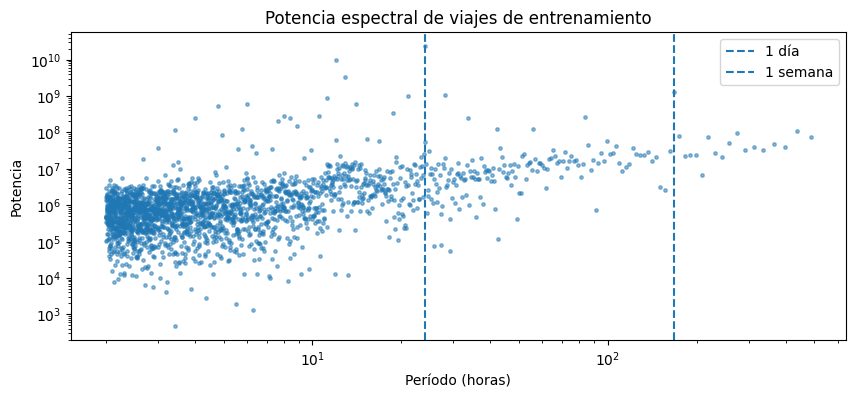

In [3]:
inicio = pd.Timestamp('2016-01-01')
slots = np.floor((train.pickup_datetime-inicio).dt.total_seconds()/1800).astype(int)
counts = np.bincount(slots, minlength=48*182).astype(float)
frecuencias = np.fft.rfftfreq(len(counts),d=0.5)  # ciclos por hora
potencia = np.abs(np.fft.rfft(counts-counts.mean()))**2
validas = (frecuencias>0)
periodos = 1/frecuencias[validas]
seleccion = (periodos>=2)&(periodos<=500)
plt.figure(figsize=(10,4))
plt.scatter(periodos[seleccion],potencia[validas][seleccion],s=6,alpha=.5)
plt.xscale('log');plt.yscale('log')
plt.axvline(24,ls='--',label='1 día');plt.axvline(168,ls='--',label='1 semana')
plt.title('Potencia espectral de viajes de entrenamiento')
plt.xlabel('Período (horas)');plt.ylabel('Potencia');plt.legend();plt.show()


## 4. Wavelet discreta de Haar (DWT) y resolución múltiple

La wavelet Haar descompone la señal temporal en una **aproximación lenta** \(A_s\) y un **detalle** \(D_s\) a escalas sucesivas. Los bloques de 2, 8 y 32 intervalos equivalen a 1, 4 y 16 horas. Con reconstrucción por bloques dyádicos:

\[
A_s(t)=\operatorname{media}\{x_j:j\text{ en bloque dyádico de tamaño }s\},
\quad D_s(t)=A_{s/2}(t)-A_s(t).
\]

La implementación en `wavelet_fft_taxi.py` utiliza solamente NumPy, **sin dependencia de PyWavelets**; se probó que reconstruye las aproximaciones y detalles de Haar por nivel.


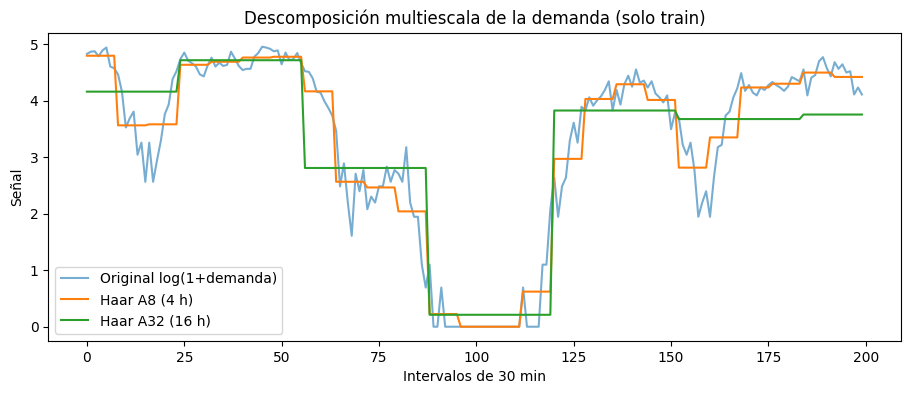

In [4]:
x = np.log1p(counts[:48*182])
coef = haar_scales(x,levels=(2,8,32))
ventana = slice(1000,1200)
plt.figure(figsize=(11,4))
plt.plot(x[ventana],label='Original log(1+demanda)',alpha=.6)
plt.plot(coef['haar_A8'][ventana],label='Haar A8 (4 h)')
plt.plot(coef['haar_A32'][ventana],label='Haar A32 (16 h)')
plt.title('Descomposición multiescala de la demanda (solo train)')
plt.xlabel('Intervalos de 30 min');plt.ylabel('Señal');plt.legend();plt.show()


## 5. Partición y control de fuga de información

Se replica exactamente la separación utilizada en el experimento anterior: `random_state=42`, con **80% entrenamiento, 10% validación y 10% holdout**. El holdout se reserva hasta elegir la configuración final. Se retiran del **ajuste** duraciones fuera de 1–43 200 segundos; las particiones usadas para **medir RMSLE no se filtran**.


In [5]:
id_train, id_temporal = train_test_split(np.arange(len(train)),test_size=.20,random_state=42)
id_val, id_hold = train_test_split(id_temporal,test_size=.50,random_state=42)
tr = train.iloc[id_train].copy()
val = train.iloc[id_val].copy()
tr = tr.loc[tr.trip_duration.between(1,43200)].copy()
log_y = np.log1p(tr.trip_duration.to_numpy())
print('Filas para ajuste:',len(tr),'validación:',len(val),'holdout sellado:',len(id_hold))
assert len(val)==70000 and len(id_hold)==70000


Filas para ajuste: 559212 validación: 70000 holdout sellado: 70000


## 6. Variables originales + armónicos periódicos

Las 81 variables de partida incluyen coordenadas, distancias geográficas, hora, día, dirección y cercanía a aeropuertos. Además se agregan **45 bases deterministas** Fourier/Haar, sin utilizar ninguna etiqueta: armónicos diarios, semanales, estacionales y componentes espaciales. Los árboles no necesitan estandarización, pero sí imputación consistente.


In [6]:
base_x = create_features(tr.iloc[:5]); harmonicos = deterministic_features(tr.iloc[:5])
print('Originales:',base_x.shape[1], 'Bases Fourier/Haar:',harmonicos.shape[1])
print('Ejemplos: ',list(harmonicos.columns[:15]))


Originales: 81 Bases Fourier/Haar: 45
Ejemplos:  ['fourier_dia_sin_2', 'fourier_dia_cos_2', 'fourier_dia_sin_3', 'fourier_dia_cos_3', 'fourier_dia_sin_4', 'fourier_dia_cos_4', 'fourier_dia_sin_6', 'fourier_dia_cos_6', 'fourier_dia_sin_8', 'fourier_dia_cos_8', 'fourier_dia_sin_12', 'fourier_dia_cos_12', 'fourier_semana_sin_1', 'fourier_semana_cos_1', 'fourier_semana_sin_2']


## 7. Estadísticas wavelet/FFT aprendidas **out-of-fold**

Para cada fold de entrenamiento se ajusta el encoder con los **otros cuatro folds**. Se calculan frecuencias históricas de pickups (sin etiquetas), sus aproximaciones/detalles Haar y bandas de Fourier. Opcionalmente se calcula una media suavizada de `log1p(trip_duration)` por media hora semanal y se descompone mediante FFT y Haar.

**Anti-leakage:** el ejemplo `i` nunca contribuye con `trip_duration[i]` a sus propias características supervisadas. Validación y test son transformados solo con el encoder construido en train, nunca con sus etiquetas. Los períodos tienen naturaleza retrospectiva (enero–junio 2016); para un sistema de producción que prediga fechas futuras se requeriría validación cronológica y cálculos causales.


In [7]:
# Demostración rápida con una muestra: no exige entrenar LightGBM.
ejemplo = tr.iloc[:1000].copy()
z_ejemplo = np.log1p(ejemplo.trip_duration.to_numpy())
enc_demostracion = FourierHaarEncoder(folds=5,seed=47)
caracteristicas_oof = enc_demostracion.fit_transform(ejemplo,z_ejemplo,supervised=True)
enc_demostracion.fit(ejemplo,z_ejemplo,supervised=True)
print('Variables OOF:',caracteristicas_oof.shape[1])
print('Sin NaN en las salidas:',bool(caracteristicas_oof.notna().all().all()))


Variables OOF: 41
Sin NaN en las salidas: True


## 8. Prueba automática de independencia de la etiqueta propia

Para verificar la codificación OOF, se altera exclusivamente el objetivo de una fila y se comprueba que **sus** variables de wavelet y Fourier supervisadas no cambian. Es una prueba local de exclusión; no reemplaza una auditoría de todo el pipeline.


In [8]:
z_alt = z_ejemplo.copy(); z_alt[0] += 3.
caracteristicas_alt = FourierHaarEncoder(folds=5,seed=47).fit_transform(ejemplo,z_alt,supervised=True)
delta = np.max(np.abs(caracteristicas_oof.iloc[0].to_numpy()-caracteristicas_alt.iloc[0].to_numpy()))
print('Cambio máximo en features de la propia fila al alterar su y:',delta)
assert delta < 1e-7


Cambio máximo en features de la propia fila al alterar su y: 0.0


## 9. Imputación y entrenamiento

El script reproducible `experimento_wavelets_fft.py` construye matrices completas (filtro solo en train, medianas aprendidas solo en train, 5 folds OOF) y ajusta **tres variantes** de LightGBM con la **misma partición** y configuración:

1. 81 variables base + 45 bases Fourier/Haar fijas = 126 variables.
2. Lo anterior + 27 wavelets/FFT de demanda, calculadas únicamente con datos de entrenamiento = 153 variables.
3. Lo anterior + 14 transformadas de medias de log-duración **OOF** = 167 variables.

Parámetros principales: `num_leaves=105`, `learning_rate=0.045`, hasta `n_estimators=1700`, `min_child_samples=75`, `reg_lambda=5`, `early_stopping(110)`. Se elige el modelo que minimiza el RMSLE de validación. **No se ha consultado el holdout para afinar parámetros.**


In [9]:
# Entrenamiento completo (varios minutos): activar solo si deseas repetir el ajuste.
EJECUTAR_ENTRENAMIENTO = False
if EJECUTAR_ENTRENAMIENTO:
    import subprocess,sys
    subprocess.run([sys.executable,'experimento_wavelets_fft.py'],check=True)
else:
    print('Se muestran a continuación los resultados del entrenamiento ya ejecutado.')


Se muestran a continuación los resultados del entrenamiento ya ejecutado.


## 10. Resultados medidos y selección de ensambles

Se incluyen **todas** las variantes, incluso las que empeoraron. Las predicciones de Fourier/Haar se combinan en **escala log** con el modelo existente, eligiendo el peso únicamente por validación. `evaluar_ensambles_wavelet.py` contrasta asimismo con el ensamble geográfico previo.


In [10]:
f = R/'resultados_wavelet'/'comparacion_completa.csv'
if not f.exists(): f=R/'resultados_wavelet'/'experimentos_wavelet.csv'
ranking=pd.read_csv(f).sort_values('rmsle_validacion')
print(ranking[['modelo','rmsle_validacion']].head(20).to_string(index=False))
print('Referencia en la plataforma reportada previamente: 0.3704 (test oculto; NO comparable directamente).')


                                             modelo  rmsle_validacion
ensemble_previo_0.75_con_Fourier_demanda_target_OOF          0.373800
      ensemble_previo_0.75_con_Fourier_demanda_Haar          0.373892
 ensemble_previo_0.5_con_Fourier_demanda_target_OOF          0.373895
        ensemble_previo_0.75_con_Fourier_Haar_fijas          0.373942
         ensemble_previo_0.5_con_Fourier_Haar_fijas          0.374007
       ensemble_previo_0.5_con_Fourier_demanda_Haar          0.374012
 ensemble_previo_0.9_con_Fourier_demanda_target_OOF          0.374184
       ensemble_previo_0.9_con_Fourier_demanda_Haar          0.374229
         ensemble_previo_0.9_con_Fourier_Haar_fijas          0.374262
       blend_ref_0.5_con_Fourier_demanda_target_OOF          0.374360
             blend_ref_0.5_con_Fourier_demanda_Haar          0.374499
               blend_ref_0.5_con_Fourier_Haar_fijas          0.374577
      blend_ref_0.75_con_Fourier_demanda_target_OOF          0.374590
                    

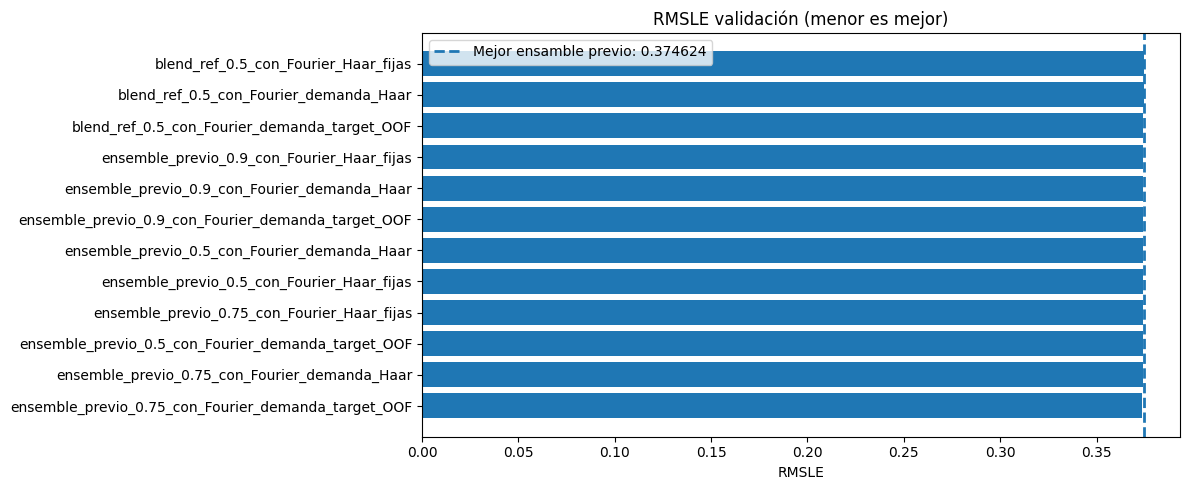

In [11]:
r=ranking[['modelo','rmsle_validacion']].head(12).sort_values('rmsle_validacion')
plt.figure(figsize=(12,5));plt.barh(r.modelo,r.rmsle_validacion)
plt.title('RMSLE validación (menor es mejor)');plt.xlabel('RMSLE')
plt.axvline(.374624017,ls='--',lw=2,label='Mejor ensamble previo: 0.374624')
plt.legend();plt.tight_layout();plt.show()


## 11. Decisión final y holdout

Primero se ordenan los RMSLE de **validación** y se selecciona un único candidato. Solo si el modelo espectral supera la referencia en validación se justifica evaluar una vez sobre holdout y, en caso de confirmarse, reajustar con todos los datos etiquetados elegibles y generar un CSV alternativo.

**No debe crearse un CSV supuestamente mejor** si la validación demuestra que el cambio aumenta el RMSLE. El `test.csv` ciego no ofrece una métrica con la cual seleccionar el modelo.


In [12]:
mejor=ranking.iloc[0]
print('Candidato:',mejor.modelo,'RMSLE:',round(mejor.rmsle_validacion,7))
print('Referencias: validación anterior 0.374624; test ciego reportado por usuario 0.3704')
if mejor.rmsle_validacion >= .374624017:
    print('Conclusión: Fourier/Haar NO mejoró el mejor ensamble en validación; no reemplazar envío.')
else:
    print('Hubo mejora en validación; verificar su evaluación sobre holdout e informe antes de enviar.')


Candidato: ensemble_previo_0.75_con_Fourier_demanda_target_OOF RMSLE: 0.3738001
Referencias: validación anterior 0.374624; test ciego reportado por usuario 0.3704
Hubo mejora en validación; verificar su evaluación sobre holdout e informe antes de enviar.


## 12. Diagnóstico y límites del objetivo 0.20

Un RMSLE de 0.20 exige reducciones muy grandes de error relativo. Hay viajes extremos cuya duración es mucho mayor de lo que puede inferirse únicamente del origen, destino y hora. Detectar periodicidades de demanda **no recupera información no observada** como tráfico real, accidentes o rutas efectivas.

También debemos distinguir **mejor validación local** y **mejor score de test oculto**: son conjuntos diferentes. No se utilizaron ni inventaron etiquetas de test. Para desplegar temporalmente hacia el futuro conviene volver a ejecutar la evaluación con un split por fecha.


## 13. Reproducibilidad y verificación

- Ejecuta en orden las celdas del notebook para explorar y entender los datos.
- Con `EJECUTAR_ENTRENAMIENTO=True` se reproducen las pruebas de 3 LightGBM (es lento).
- `python evaluar_ensambles_wavelet.py` reconstruye la comparación con el ensamble geográfico anterior.
- El archivo `resultados_wavelet/comparacion_completa.csv` conserva el ranking real.
- Solo en caso de superar validación y holdout debe generarse un nuevo `submission.csv` de 100,000 IDs únicos y predicciones >= 0, sin columnas adicionales.

**Dependencias:** `numpy`, `pandas`, `scikit-learn`, `scipy` (gráficas), `lightgbm`, `matplotlib`, `joblib`, `nbformat`. *La wavelet Haar está implementada con NumPy*.


## 14. Confirmación con holdout del ensamble elegido

Tras escoger el ensamble **75% modelo geográfico previo + 25% Fourier/Haar** exclusivamente con la validación, el script `evaluar_holdout_wavelet.py` lo evaluó **una vez** sobre los 70,000 ejemplos reservados. El resultado se lee del archivo `holdout_final.json`; no se empleó para reajustar los pesos. Si se quiere desplegar hacia nuevas fechas, se necesita una validación cronológica adicional.


In [13]:
import json
validacion = json.loads((R/'resultados_wavelet'/'ganador_final_validacion.json').read_text())
holdout = json.loads((R/'resultados_wavelet'/'holdout_final.json').read_text())
print('Mejor RMSLE validación:',round(validacion['mejor']['rmsle_validacion'],6))
print('RMSLE holdout anterior:',round(holdout['rmsle_holdout_ensamble_previo'],6))
print('RMSLE holdout con Fourier/Haar:',round(holdout['rmsle_holdout_wavelet'],6))
print('Reducción RMSLE holdout:',round(holdout['mejora'],6))


Mejor RMSLE validación: 0.3738
RMSLE holdout anterior: 0.379288
RMSLE holdout con Fourier/Haar: 0.37859
Reducción RMSLE holdout: 0.000699


## 15. Auditoría del CSV final y limitaciones

El reentrenamiento final usa los registros elegibles de `train.csv` y aplica el modelo aprendido sobre `test.csv` ciego. Se verifican el número de filas, el orden e identidad de todos los IDs, el nombre exacto de las columnas y la ausencia de valores no numéricos o negativos. Se reprodujeron las 100,000 predicciones desde los modelos serializados con diferencia máxima de aproximadamente `9.1e-13` segundos.

**No existe evidencia de haber alcanzado 0.20 ni de superar el 0.3704 en el test oficial:** este último requiere enviar el nuevo CSV a la plataforma.


In [14]:
submission = pd.read_csv(R/'submission_wavelet_fft.csv')
assert submission.columns.tolist()==['id','trip_duration']
assert len(submission)==len(test)==100000
assert submission.id.is_unique
assert np.array_equal(submission.id.to_numpy(), test.id.to_numpy())
assert pd.api.types.is_numeric_dtype(submission.trip_duration)
assert np.isfinite(submission.trip_duration.to_numpy()).all()
assert (submission.trip_duration>=0).all()
print('CSV válido:',submission.shape,'duración mediana (s):',round(submission.trip_duration.median(),2))
print(submission.head(5).to_string(index=False))


CSV válido: (100000, 2) duración mediana (s): 652.49
                              id  trip_duration
036771038fbe404fabdf699955443500     717.424397
2ea1c0ddab68440e9a6183ee6e32aeef     799.488908
eb2d997eea384112bd74146b48b461dd     399.225284
c104ede33a344de0bf1d7ced9cbb9c7c     411.878101
fd4d0e3c804a4c9f97cebfac386f7ed4     937.857470
